# First Python Program on a Public Dataset: Iris Flower Analysis

**Dataset Source:** [UCI Machine Learning Repository - Iris Data Set](https://archive.ics.uci.edu/dataset/53/iris)  
**Author:** Tharun Godwin C  
**Tools Used:** Python 3, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook  

---

### Project Overview
This project presents an exploratory data analysis (EDA) on the internationally recognized **Iris Data Set** hosted by the **UCI Machine Learning Repository**. The goal is to:
1. Load and inspect the public dataset using `pandas`.
2. Compute descriptive statistics and feature correlations using `numpy` and `pandas`.
3. Create clear, informative data visualizations with `matplotlib` and `seaborn`.
4. Summarize the analytical findings in plain words.

## 1. Import Required Libraries
We import `pandas` for data manipulation, `numpy` for mathematical calculations, and `matplotlib` & `seaborn` for generating charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 11

print("Libraries imported successfully!")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")


Libraries imported successfully!
Pandas version: 3.0.5
NumPy version: 1.26.4


## 2. Load Dataset from UCI Machine Learning Repository
The dataset is loaded from our local copy `data/iris.csv` with a fallback mechanism that can fetch directly from the official UCI repository URL.

In [2]:
data_path = "data/iris.csv"
uci_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"
columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]

try:
    df = pd.read_csv(data_path)
    print("Loaded dataset from local file: data/iris.csv")
except Exception:
    df = pd.read_csv(uci_url, header=None, names=columns)
    df["species"] = df["species"].str.replace("Iris-", "")
    print("Loaded dataset from UCI Machine Learning Repository URL")

print("\n--- First 5 Rows of the Dataset ---")
df.head()


Loaded dataset from local file: data/iris.csv

--- First 5 Rows of the Dataset ---


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Data Structure & Integrity Check
We verify dataset shape, data types, and check for missing values to ensure data quality.

In [3]:
print(f"Dataset Shape: {df.shape[0]} rows × {df.shape[1]} columns\n")
print("--- Dataset Information ---")
df.info()

print("\n--- Missing Values Count ---")
print(df.isnull().sum())

print("\n--- Class Frequency Distribution ---")
print(df["species"].value_counts())


Dataset Shape: 150 rows × 5 columns

--- Dataset Information ---
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB

--- Missing Values Count ---
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

--- Class Frequency Distribution ---
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## 4. Statistical Analysis with NumPy and Pandas
We compute overall descriptive statistics, average measurements per species, and the Pearson correlation matrix.

In [4]:
print("--- Overall Descriptive Statistics ---")
print(df.describe().round(2))

# Aggregated metrics per species using pandas & numpy
print("\n--- Average Feature Measurements by Species (in cm) ---")
species_stats = df.groupby("species").agg(
    mean_sepal_length=("sepal_length", np.mean),
    mean_sepal_width=("sepal_width", np.mean),
    mean_petal_length=("petal_length", np.mean),
    mean_petal_width=("petal_width", np.mean)
)
print(species_stats.round(2))

# Pearson correlation between numeric features
print("\n--- Correlation Matrix ---")
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()
print(corr_matrix.round(3))


--- Overall Descriptive Statistics ---
       sepal_length  sepal_width  petal_length  petal_width
count        150.00       150.00        150.00       150.00
mean           5.84         3.05          3.76         1.20
std            0.83         0.43          1.76         0.76
min            4.30         2.00          1.00         0.10
25%            5.10         2.80          1.60         0.30
50%            5.80         3.00          4.35         1.30
75%            6.40         3.30          5.10         1.80
max            7.90         4.40          6.90         2.50

--- Average Feature Measurements by Species (in cm) ---
            mean_sepal_length  mean_sepal_width  mean_petal_length  \
species                                                              
setosa                   5.01              3.42               1.46   
versicolor               5.94              2.77               4.26   
virginica                6.59              2.97               5.55   

            m

## 5. Data Visualizations

### Chart 1: Petal Length vs. Petal Width across Species
A scatter plot demonstrating cluster separation and the correlation between petal dimensions.

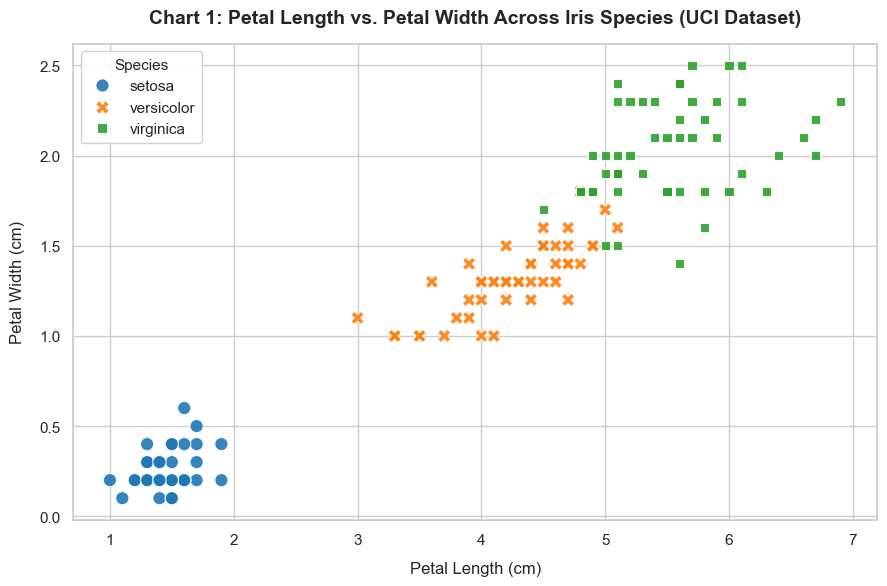

In [5]:
plt.figure(figsize=(9, 6))

species_palette = {
    "setosa": "#1f77b4",
    "versicolor": "#ff7f0e",
    "virginica": "#2ca02c"
}

sns.scatterplot(
    data=df,
    x="petal_length",
    y="petal_width",
    hue="species",
    style="species",
    s=90,
    palette=species_palette,
    alpha=0.9,
    edgecolor="w"
)

plt.title("Chart 1: Petal Length vs. Petal Width Across Iris Species (UCI Dataset)", fontsize=14, pad=15, fontweight="bold")
plt.xlabel("Petal Length (cm)", fontsize=12, labelpad=10)
plt.ylabel("Petal Width (cm)", fontsize=12, labelpad=10)
plt.legend(title="Species", title_fontsize=11, loc="upper left", frameon=True, framealpha=0.9)
plt.tight_layout()
plt.savefig("chart1_petal_dimensions.png", dpi=300)
plt.show()


### Chart 2: Morphological Feature Distributions by Species
Comparative box plots showing the median, interquartile ranges, and variance of Petal Length and Sepal Length.

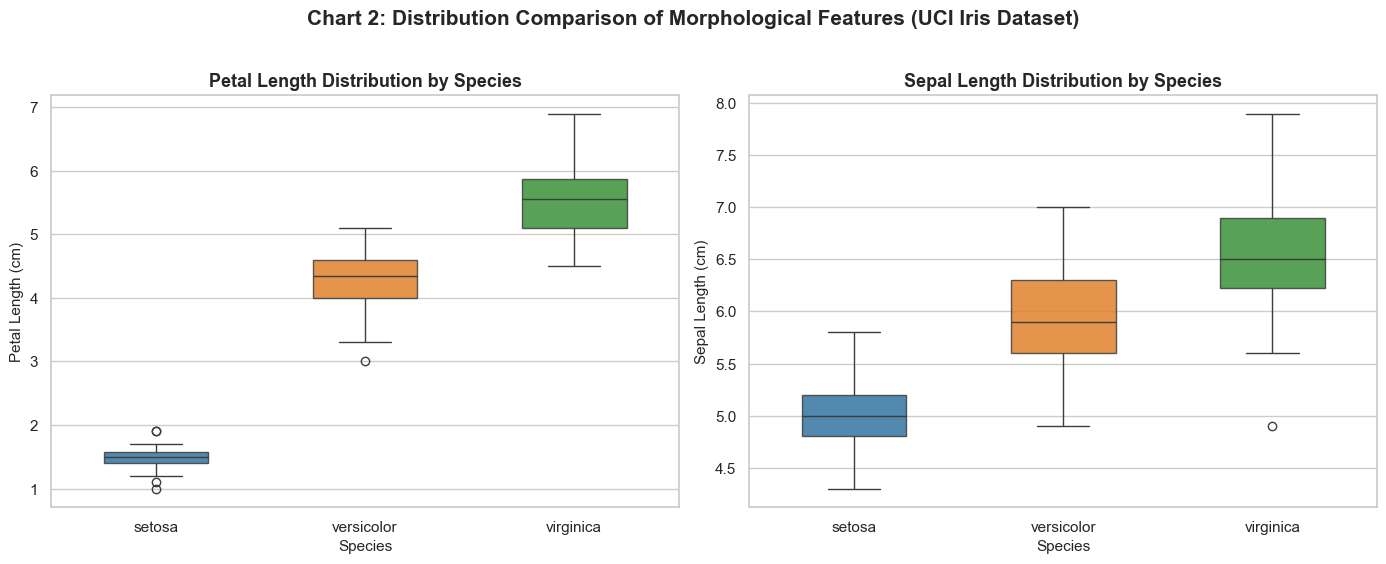

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=False)

# Subplot 1: Petal Length
sns.boxplot(
    ax=axes[0],
    data=df,
    x="species",
    y="petal_length",
    hue="species",
    palette=species_palette,
    legend=False,
    boxprops=dict(alpha=0.85),
    width=0.5
)
axes[0].set_title("Petal Length Distribution by Species", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Species", fontsize=11)
axes[0].set_ylabel("Petal Length (cm)", fontsize=11)

# Subplot 2: Sepal Length
sns.boxplot(
    ax=axes[1],
    data=df,
    x="species",
    y="sepal_length",
    hue="species",
    palette=species_palette,
    legend=False,
    boxprops=dict(alpha=0.85),
    width=0.5
)
axes[1].set_title("Sepal Length Distribution by Species", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Species", fontsize=11)
axes[1].set_ylabel("Sepal Length (cm)", fontsize=11)

fig.suptitle("Chart 2: Distribution Comparison of Morphological Features (UCI Iris Dataset)", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("chart2_feature_distributions.png", dpi=300)
plt.show()


## 6. Key Findings in Plain Words

From the exploratory analysis and charts, several key insights emerge:

1. **Iris Setosa is Completely Distinct:**
   - *Iris setosa* is immediately separable from the other two species without any overlap. Its petals are tiny, averaging only **1.46 cm in length** and **0.24 cm in width**.
   - In Chart 1, all Setosa samples cluster together in the bottom-left corner.

2. **High Petal Dimensions Correlation ($r = 0.963$):**
   - Petal length and petal width have an exceptionally strong positive linear correlation. When a flower develops a longer petal, it almost always develops a proportionally wider petal.

3. **Separating Versicolor and Virginica:**
   - While *Iris versicolor* and *Iris virginica* have slight overlap in sepal lengths (between 5.5 cm and 6.5 cm), their petal measurements clearly separate them:
     - *Versicolor* petals average **4.26 cm** in length and **1.33 cm** in width.
     - *Virginica* petals average **5.55 cm** in length and **2.03 cm** in width.
   - Petal length is therefore the single most powerful feature for classifying these species.

4. **Balanced & Clean Data:**
   - The dataset contains exactly **50 observations per species** (150 total) and **0 missing values**, making it one of the cleanest benchmark datasets for learning data analysis.

## 7. Conclusion
This first Python program demonstrated the foundational steps of data science:
- Loading real-world data from a renowned public repository (**UCI Machine Learning Repository**).
- Performing exploratory data profiling and numerical operations with `pandas` and `numpy`.
- Designing clear, high-contrast visual charts with `matplotlib` and `seaborn`.
- Translating data patterns into clear, plain-language insights.